# BART before and after fine-tuning

Compares the configured pretrained `facebook/bart-base` model with the local fine-tuned BART checkpoint on the same findings/impression examples. Uses identical tokenization limits, beam count, generation length, ROUGE scoring, and a fixed sample. The baseline is loaded from the local Hugging Face cache by default; enabling downloads is an explicit setting.

No training is performed. Missing local inputs or checkpoints are reported rather than fabricated.

## Check data and select the paired evaluation examples

Reuse the saved fine-tuned predictions when present so both models are scored on the identical rows. Otherwise, select a deterministic sample from the current processed test CSV.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src').is_dir() and (p/'data').is_dir())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'results'))
from utils.evaluation import setup,save,meta
ROOT=setup(ROOT);OUT=ROOT/'results'
import pandas as pd
from src.summarization import config
pred_path=OUT/'tables/summarization_predictions.csv'
test_path=config.TEST_FILE
if pred_path.exists():
 paired=pd.read_csv(pred_path)[['findings','reference']].dropna().drop_duplicates().reset_index(drop=True)
 print('Reusing fine-tuned evaluation sample:',len(paired))
elif test_path.exists():
 data=pd.read_csv(test_path)[['findings','impression']].dropna().copy()
 data.columns=['findings','reference'];data=data.drop_duplicates().reset_index(drop=True)
 paired=data.sample(n=min(100,len(data)),random_state=42).reset_index(drop=True)
 print('Sampled examples:',len(paired))
else:
 paired=pd.DataFrame(columns=['findings','reference']);print('UNAVAILABLE: processed test CSV missing:',test_path)
print('Configured pretrained model:',config.MODEL_NAME,'fine-tuned checkpoint:',config.CHECKPOINT_DIR)


Reusing fine-tuned evaluation sample: 100
Configured pretrained model: facebook/bart-base fine-tuned checkpoint: D:\DevLab\Projects\CDSS_Final\models\summarization\checkpoint-68658


## Run the two models with identical generation settings

No model is downloaded unless `ALLOW_MODEL_DOWNLOAD=True`. Models are loaded sequentially to limit GPU memory use. The fine-tuned checkpoint is run on the same paired rows; local dependency or checkpoint errors are recorded explicitly.

In [2]:
import gc,torch,numpy as np, matplotlib.pyplot as plt
from transformers import AutoTokenizer,BartForConditionalGeneration
from rouge_score.rouge_scorer import RougeScorer
ALLOW_MODEL_DOWNLOAD=False
scorer=RougeScorer(['rouge1','rouge2','rougeL'],use_stemmer=True)
def run_bart(model_ref, frame, tag):
 local_only=not ALLOW_MODEL_DOWNLOAD
 tok=AutoTokenizer.from_pretrained(str(model_ref),local_files_only=local_only)
 model=BartForConditionalGeneration.from_pretrained(str(model_ref),local_files_only=local_only)
 device=torch.device('cuda' if torch.cuda.is_available() else 'cpu');model.to(device).eval(); rows=[]
 for i,row in frame.iterrows():
  z=tok(str(row.findings),return_tensors='pt',truncation=True,max_length=config.MAX_INPUT_LENGTH).to(device)
  with torch.inference_mode(): ids=model.generate(**z,max_length=config.GENERATION_MAX_LENGTH,num_beams=config.NUM_BEAMS,early_stopping=True)
  text=tok.decode(ids[0],skip_special_tokens=True); scores=scorer.score(str(row.reference),text)
  rows.append({'prediction_'+tag:text,**{k+'_'+tag:v.fmeasure for k,v in scores.items()}})
 del model,tok;gc.collect()
 if torch.cuda.is_available():torch.cuda.empty_cache()
 return pd.DataFrame(rows),str(device)
comparison=paired.copy(); availability={}; devices={}
if len(paired):
 for tag,ref in [('pretrained',config.MODEL_NAME),('finetuned',config.CHECKPOINT_DIR)]:
  try:
   result,dev=run_bart(ref,paired,tag);comparison=pd.concat([comparison,result],axis=1);availability[tag]='MEASURED';devices[tag]=dev
  except Exception as exc:
   availability[tag]=f'UNAVAILABLE: {type(exc).__name__}: {exc}';print(tag,availability[tag])
else: availability={'pretrained':'NOT RUN: no examples','finetuned':'NOT RUN: no examples'}


Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

## Metrics, paired uncertainty, and outputs

Report means and paired bootstrap intervals for the score difference (fine-tuned minus pretrained). These intervals describe this sample; they are not a clinical validation or a claim of statistical significance.

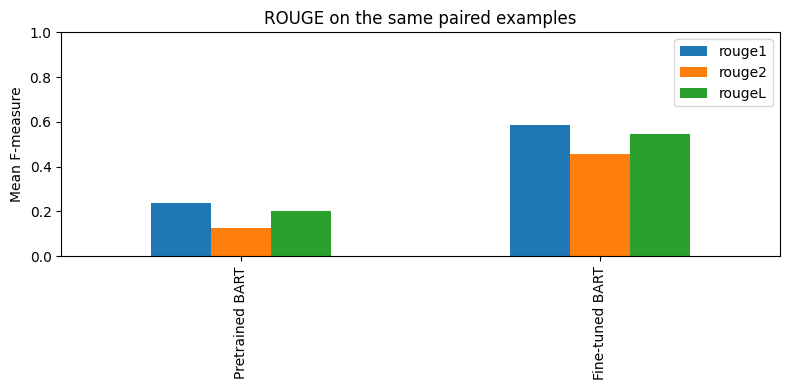

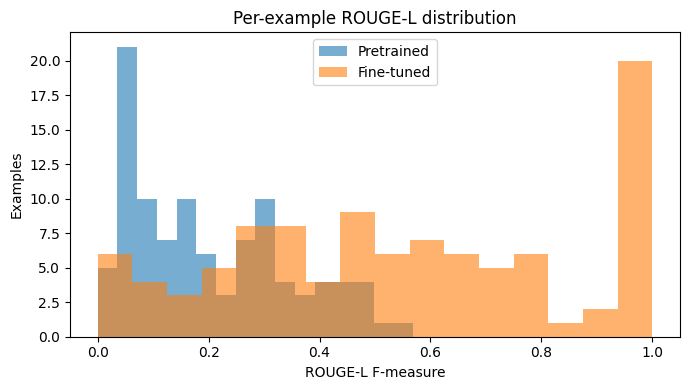

{'n': 100, 'availability': {'pretrained': 'MEASURED', 'finetuned': 'MEASURED'}, 'devices': {'pretrained': 'cuda', 'finetuned': 'cuda'}, 'pretrained_model': 'facebook/bart-base', 'fine_tuned_checkpoint': 'D:\\DevLab\\Projects\\CDSS_Final\\models\\summarization\\checkpoint-68658', 'seed': 42, 'generation': {'max_input_length': 512, 'max_length': 128, 'num_beams': 4}, 'pretrained_rouge1': 0.2400061878434216, 'finetuned_rouge1': 0.587871956760815, 'rouge1_delta_finetuned_minus_pretrained': 0.3478657689173935, 'rouge1_delta_ci95': [0.2790314405936593, 0.4239504285727417], 'pretrained_rouge2': 0.12587324954432488, 'finetuned_rouge2': 0.4566039569278416, 'rouge2_delta_finetuned_minus_pretrained': 0.3307307073835167, 'rouge2_delta_ci95': [0.25884234392570693, 0.41326508896250036], 'pretrained_rougeL': 0.20124839355886098, 'finetuned_rougeL': 0.5464693141407192, 'rougeL_delta_finetuned_minus_pretrained': 0.34522092058185827, 'rougeL_delta_ci95': [0.27854925242190937, 0.41982946496107826]}


In [3]:
from datetime import datetime,timezone
metric_names=['rouge1','rouge2','rougeL'];metrics={'n':len(comparison),'availability':availability,'devices':devices,'pretrained_model':config.MODEL_NAME,'fine_tuned_checkpoint':str(config.CHECKPOINT_DIR),'seed':42,'generation':{'max_input_length':config.MAX_INPUT_LENGTH,'max_length':config.GENERATION_MAX_LENGTH,'num_beams':config.NUM_BEAMS}}
for name in metric_names:
 for tag in ['pretrained','finetuned']:
  col=f'{name}_{tag}'
  if col in comparison:metrics[f'{tag}_{name}']=float(comparison[col].mean())
 if f'{name}_pretrained' in comparison and f'{name}_finetuned' in comparison:
  delta=(comparison[f'{name}_finetuned']-comparison[f'{name}_pretrained']).to_numpy();rng=np.random.default_rng(42);boot=np.array([rng.choice(delta,len(delta),replace=True).mean() for _ in range(2000)])
  metrics[f'{name}_delta_finetuned_minus_pretrained']=float(delta.mean());metrics[f'{name}_delta_ci95']=[float(np.quantile(boot,.025)),float(np.quantile(boot,.975))]
if len(comparison):
 comparison.to_csv(OUT/'tables/summarization_bart_comparison.csv',index=False)
 if all(f'{k}_{tag}' in comparison for k in metric_names for tag in ['pretrained','finetuned']):
  means=pd.DataFrame({k:[metrics.get('pretrained_'+k,np.nan),metrics.get('finetuned_'+k,np.nan)] for k in metric_names},index=['Pretrained BART','Fine-tuned BART']);means.plot.bar(figsize=(8,4),ylim=(0,1),title='ROUGE on the same paired examples',ylabel='Mean F-measure');plt.tight_layout();plt.savefig(OUT/'figures/summarization_pretrained_vs_finetuned.png',dpi=150);plt.show()
  fig,ax=plt.subplots(figsize=(7,4));ax.hist(comparison['rougeL_pretrained'],bins=16,alpha=.6,label='Pretrained');ax.hist(comparison['rougeL_finetuned'],bins=16,alpha=.6,label='Fine-tuned');ax.set(title='Per-example ROUGE-L distribution',xlabel='ROUGE-L F-measure',ylabel='Examples');ax.legend();fig.tight_layout();fig.savefig(OUT/'figures/summarization_pretrained_vs_finetuned_examples.png',dpi=150);plt.show()
save(OUT/'metrics/summarization_pretrained_vs_finetuned.json',meta(ROOT,'summarization_before_after',metrics=metrics,evaluation_date=datetime.now(timezone.utc).isoformat()))
print(metrics)


## Inspect paired examples and limitations

A higher ROUGE score means more lexical overlap, not better preservation of negation, laterality, anatomy, or uncertainty. Review examples and clinically important errors manually. This notebook does not claim clinician validation.

In [4]:
if 'rougeL_pretrained' in comparison and 'rougeL_finetuned' in comparison:
 delta=(comparison.rougeL_finetuned-comparison.rougeL_pretrained); examples=comparison.assign(rougeL_delta=delta).sort_values('rougeL_delta')
 display(examples.iloc[[0,len(examples)//2,-1]][['findings','reference','prediction_pretrained','prediction_finetuned','rougeL_pretrained','rougeL_finetuned','rougeL_delta']])
else: print('Example comparison unavailable until both models run.')

,findings,reference,prediction_pretrained,prediction_finetuned,rougeL_pretrained,rougeL_finetuned,rougeL_delta
84,Left Internal jugular venous catheter terminat...,Left internal jugular venous catheter terminat...,Left Internal jugular venous catheter terminat...,No acute cardiopulmonary process.,0.418605,0.0,-0.418605
28,Right-sided Port-A-Cath terminates in the mid ...,No acute cardiopulmonary process.,Right-sided Port-A-Cath terminates in the mid ...,No acute radiographic intrathoracic pulmonary ...,0.102564,0.4,0.297436
30,Frontal and lateral views of the chest were ob...,No acute cardiopulmonary process.,Frontal and lateral views of the chest were ob...,No acute cardiopulmonary process.,0.034483,1.0,0.965517
